**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**02 | Reading Behaviour and Statistical Analysis**

![Reading Behaviour and Statistical Analysis — scientific workflow](../../images/02_reading_behaviour_and_statistics.svg)

**Objective:** Describe pre-answer eye movements, derive trial features and ordered sequences, and examine exploratory associations with response correctness.

**Dataset:** Matched eligible paragraph trials and fixed participant assignments from Notebook 01.

**Scope:** Construct scalar gaze and paragraph features, aligned fixation sequences and exploratory Training-only associations.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import (
    acquire_reports, read_report, make_cohort,
    validate_splits, validate_trial_index,
)
from reading_features import build_features, GAZE, TEXT
from reading_statistics import reading_associations

# ------------------- 7. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "onestop" / "ordinary"
processed = root / "data" / "processed" / "onestop"
processed.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", out_dir)
print("Source directory:", raw_dir)
print("Local data directory:", processed)
print("Python:", sys.version.split()[0])


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/onestop/ordinary
Local data directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/onestop
Python: 3.13.16


**02. Load the Fixed Cohort and Paragraph Reports**

Use the eligible trial identities and participant assignments from Notebook 01. Reconcile the original paragraph reports against the trial index before feature extraction. All 9,718 eligible trials retain their original metadata, outcome labels and split assignments.

In [3]:
# ============== 02. Load the Fixed Cohort and Paragraph Reports ==============

# ------------------- 1. Load Trial and Participant Tables --------------------
trials = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
trials["is_correct"] = trials.is_correct.astype(int)
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
validate_splits(trials,splits)

# -------------------- 2. Read Original Paragraph Reports ---------------------
reports = acquire_reports(raw_dir)
fix = read_report(reports["fixations"],"fixations")
ia = read_report(reports["ia"],"ia")

# ------------------- 3. Reconcile Source Trial Identities --------------------
current, _ = make_cohort(fix,ia)
validate_trial_index(trials,current)
del current


**03. Extract Reading and Text Features**

Aggregate valid fixations using duration in milliseconds and screen coordinates in pixels. The ten gaze predictors describe fixation count and duration, coordinate dispersion, scanpath length, backward word-index transitions, visited-word fraction and mean word dwell time. Backward word-index transitions are a proxy for regressions, not a validated saccade detector.

The four static text predictors describe whole-paragraph word count, mean word length, punctuation fraction and difficulty. Source frequency and surprisal summaries are descriptive only and are excluded from modelling because report coverage and layout may vary.

The feature table contains 9,718 rows with finite values for all 14 scalar predictors. Ordered sequences contain fixation duration, x and y coordinates and interest-area index. The array has shape `(9718, 256, 4)` (trial, position, feature); 193 trials (1.99%) exceed the sequence length. Scalar summaries use the full valid fixation sequence. The ordered representation retains the first 256 valid fixations, with an explicit padding mask. The full-cohort descriptive summary is not used to fit preprocessing or select models.

In [4]:
# =================== 03. Extract Reading and Text Features ===================

# ------------------ 1. Compute Trial Features and Sequences ------------------
table, x, mask = build_features(trials,fix,ia,max_fixations=256)
validate_splits(table,splits)

# ----------------------- 2. Align Whole-Paragraph Text -----------------------
paragraph_text = (ia[["participant_id","trial_index","paragraph"]].drop_duplicates()
                  .merge(trials[["participant_id","trial_index","trial_id"]],
                         on=["participant_id","trial_index"],validate="one_to_one")
                  [["trial_id","paragraph"]])
if len(paragraph_text)!=len(table):
    raise ValueError("Missing paragraph text")

# ----------------- 3. Describe Feature and Sequence Support ------------------
print("Feature rows:",len(table))
print("Sequence shape:",x.shape)
print("Truncated sequences:",int(table.sequence_truncated.sum()))
display(table[GAZE+TEXT].describe().T)
del fix, ia


Feature rows: 9718
Sequence shape: (9718, 256, 4)
Truncated sequences: 193


,count,mean,std,min,25%,50%,75%,max
fix_count,9718.0,114.632023,53.867637,22.000000,76.000000,104.000000,142.000000,814.000000
fix_total_ms,9718.0,22175.023050,11679.378765,4003.000000,13953.750000,19703.000000,27672.750000,192776.000000
fix_mean_ms,9718.0,191.235830,27.872146,117.881720,172.480807,189.245607,206.893838,395.180723
fix_sd_ms,9718.0,78.437593,29.884852,29.082574,62.654587,73.966587,88.188414,755.199387
x_sd_px,9718.0,508.956625,24.784738,409.898854,492.850489,509.680809,525.355278,630.190498
y_sd_px,9718.0,224.189603,61.749655,82.858372,173.069119,222.554957,269.512433,575.573421
path_px,9718.0,33442.116956,14841.935405,7767.042475,22941.693835,30507.513022,40089.838886,168408.001654
backward_word_rate,9718.0,0.241678,0.076118,0.000000,0.189655,0.243697,0.294118,0.480519
visited_word_fraction,9718.0,0.642881,0.114841,0.269504,0.561905,0.649573,0.726546,0.950820
mean_word_dwell_ms,9718.0,202.204716,91.609097,44.773050,137.731841,185.555485,246.032357,1251.761364


**04. Describe Reading Behaviour on Training Trials**

Restrict exploratory behaviour summaries to the 5,831 Training trials from 108 participants in Protocol A. Average each gaze feature within participant and response class before summarising across participants, so people with more trials do not receive greater weight. All 108 participants contribute to both response groups.

Participant-balanced mean fixation duration is 189.95 ms for incorrect responses and 189.73 ms for correct responses. The boxplots show substantially overlapping distributions. The small descriptive difference does not establish equivalence or predictive discrimination.

,0,1
is_correct,0.000000,1.000000
fix_count_mean,117.735451,115.141029
fix_count_std,37.827866,33.009186
fix_count_count,108.000000,108.000000
fix_total_ms_mean,22685.761615,22186.371457
fix_total_ms_std,9138.607794,8260.672001
fix_total_ms_count,108.000000,108.000000
fix_mean_ms_mean,189.949473,189.734908
fix_mean_ms_std,26.218036,25.470337
fix_mean_ms_count,108.000000,108.000000


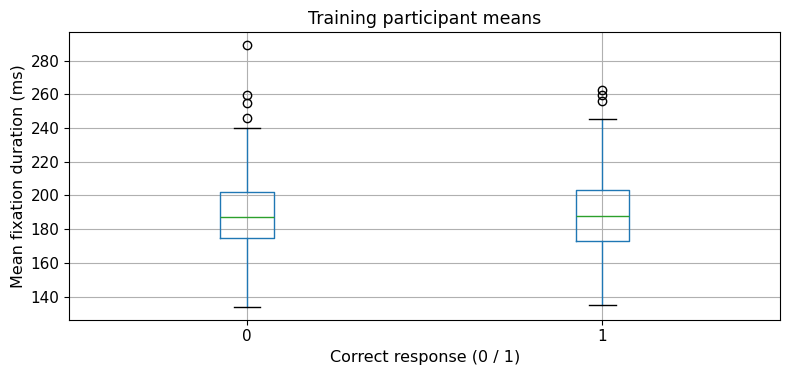

In [5]:
# ============= 04. Describe Reading Behaviour on Training Trials =============

# --------------------- 1. Identify Training Participants ---------------------
train_ids = splits.loc[splits.protocol.eq("A_unseen_people") &
                       splits.role.eq("train"),"participant_id"]
train = table[table.participant_id.isin(train_ids)].copy()

# ---------------- 2. Summarise Participant Reading Behaviour -----------------
person = train.groupby(["participant_id","is_correct"])[GAZE].mean().reset_index()
summary = person.groupby("is_correct")[GAZE].agg(["mean","std","count"])
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index()
display(summary.T)

# ------------------- 3. Plot Participant Fixation Duration -------------------
fig, ax = plt.subplots(figsize=(8,4))
person.boxplot(column="fix_mean_ms",by="is_correct",ax=ax)
fig.suptitle("")
ax.set(title="Training participant means",xlabel="Correct response (0 / 1)",ylabel="Mean fixation duration (ms)")
fig.tight_layout()
save_figure(fig,out_dir/"02_reading_behaviour.png")
plt.show()


**05. Estimate Crossed Participant and Paragraph Associations**

Fit a separate exploratory Bayesian logistic mixed-effects model for each standardised gaze feature, adjusting for difficulty and including crossed participant and paragraph random intercepts. The models use Protocol A Training data (5,831 trials, 108 participants and 162 paragraphs). All ten variational fits report successful optimiser convergence.

Backward word-index transition rate has the largest positive posterior mean (0.137 log odds per SD; approximate 95% posterior interval 0.068 to 0.206), followed by visited-word fraction (0.123; 0.055 to 0.191). Horizontal coordinate dispersion has a negative estimate (−0.076; −0.145 to −0.007). Six intervals are wholly positive, one is wholly negative and three include zero.

The plot displays approximate posterior intervals for separate difficulty-adjusted associations. These are not joint effects, causal estimates or multiplicity-adjusted confirmatory tests. Optimiser convergence does not establish predictive value.

,feature,n_trials,n_people,n_paragraphs,log_odds_per_sd,posterior_sd,approx_low,approx_high,converged
0,fix_count,5831,108,162,0.083007,0.035774,0.012890,0.153125,True
1,fix_total_ms,5831,108,162,0.091661,0.036568,0.019988,0.163334,True
2,fix_mean_ms,5831,108,162,0.039186,0.034789,-0.029002,0.107373,True
3,fix_sd_ms,5831,108,162,-0.049957,0.031761,-0.112209,0.012295,True
4,x_sd_px,5831,108,162,-0.076274,0.035104,-0.145078,-0.007470,True
5,y_sd_px,5831,108,162,-0.017967,0.035151,-0.086863,0.050930,True
6,path_px,5831,108,162,0.096979,0.035707,0.026992,0.166965,True
7,backward_word_rate,5831,108,162,0.136765,0.035110,0.067949,0.205580,True
8,visited_word_fraction,5831,108,162,0.122561,0.034721,0.054508,0.190615,True
9,mean_word_dwell_ms,5831,108,162,0.084754,0.036468,0.013277,0.156231,True


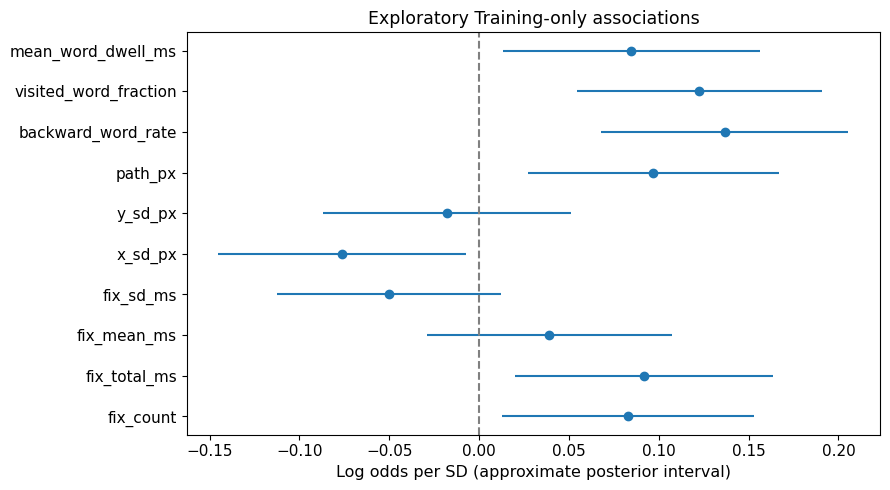

In [6]:
# ======== 05. Estimate Crossed Participant and Paragraph Associations ========

# ------------------- 1. Estimate Exploratory Associations --------------------
associations = reading_associations(train)
display(associations)
if associations.empty:
    raise ValueError("No estimable exploratory associations")

# ------------------ 2. Plot Approximate Posterior Intervals ------------------
fig, ax = plt.subplots(figsize=(9,5))
pos = np.arange(len(associations))
ax.hlines(pos,associations.approx_low,associations.approx_high)
ax.scatter(associations.log_odds_per_sd,pos)
ax.axvline(0,color="grey",linestyle="--")
ax.set_yticks(pos,associations.feature)
ax.set(xlabel="Log odds per SD (approximate posterior interval)",title="Exploratory Training-only associations")
fig.tight_layout()
save_figure(fig,out_dir/"02_reading_associations.png")
plt.show()


**06. Save Feature Tables and Local Sequence Arrays**

Save the trial-level feature table, participant-balanced summaries, association estimates and both figures to `output/`. The local files `data/processed/onestop/02_paragraph_text.csv` and `data/processed/onestop/02_fixation_sequences.npz` contain whole-paragraph text and aligned fixation arrays with a valid-position mask, respectively. These two intermediate representations are generated from the source reports for subsequent modelling.

Notebook 03 uses the feature table and local paragraph-text file; Notebook 04 uses the same feature table and the local sequence cache. Both use the trial index and participant assignments from Notebook 01.

In [7]:
# ============= 06. Save Feature Tables and Local Sequence Arrays =============

# ---------------------- 1. Save Derived Feature Tables -----------------------
table.to_csv(out_dir/"02_trial_features.csv",index=False)
summary.to_csv(out_dir/"02_training_behaviour.csv",index=False)
associations.to_csv(out_dir/"02_training_associations.csv",index=False)

# ------------------ 2. Save Local Text and Sequence Arrays -------------------
paragraph_text.to_csv(processed/"02_paragraph_text.csv",index=False)
np.savez_compressed(processed/"02_fixation_sequences.npz",
                    trial_id=table.trial_id.to_numpy(str),x=x,mask=mask)

# ------------------------ 3. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"02")


------------------------------------------------------------------------
Notebook 02
Files packaged: 5
  + 02_reading_associations.png
  + 02_reading_behaviour.png
  + 02_training_associations.csv
  + 02_training_behaviour.csv
  + 02_trial_features.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_02_Outputs.zip
